# MNIST Classification with a Restricted Boltzmann Machine (RBM)

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import BernoulliRBM
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.base import clone
import time

In [38]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [39]:
# Dataset
(X_train_img, y_train), (X_test_img, y_test) = mnist.load_data()
X_train_img.shape, y_train.shape, X_test_img.shape, y_test.shape

((60000, 28, 28), (60000,), (10000, 28, 28), (10000,))

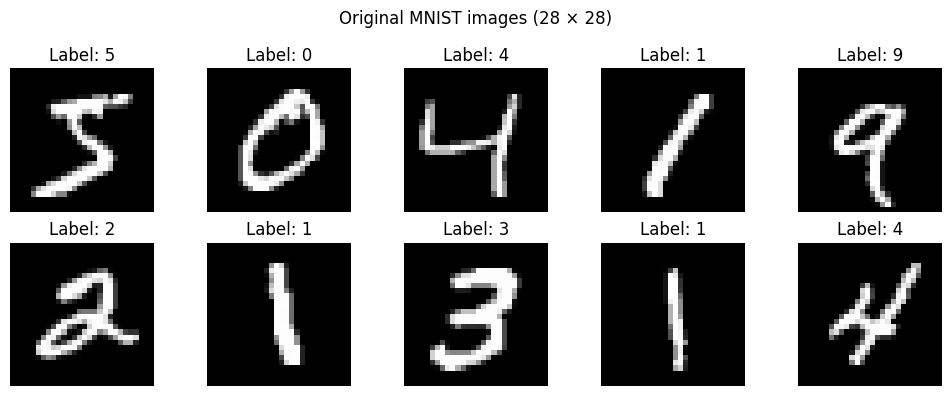

In [40]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train_img[i], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Label: {y_train[i]}')
    ax.axis('off')
plt.suptitle('Original MNIST images (28 × 28)')
plt.tight_layout()
plt.show()

In [41]:
# Selecting a subset of data for class demo
X_train = X_train_img[0:10000]
y_train = y_train[0:10000]
X_test = X_test_img[0:1000]
y_test = y_test[0:1000]
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((10000, 28, 28), (10000,), (1000, 28, 28), (1000,))

In [42]:
# Flatten & Normalization
X_train = X_train.reshape(-1, 28 * 28).astype(np.float32) / 255.0
X_test = X_test.reshape(-1, 28 * 28).astype(np.float32) / 255.0
print('X_train:', X_train.shape, 'X_test:', X_test.shape)
print('Normalized range:', X_train.min(), X_train.max())


X_train: (10000, 784) X_test: (1000, 784)
Normalized range: 0.0 1.0


## Baseline: Logistic Regression on raw pixels

In [43]:
baseline = LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)
t0 = time.perf_counter()

baseline.fit(X_train, y_train)
y_raw_pred = baseline.predict(X_test)
print('Training time:', time.perf_counter() - t0)
raw_accuracy = accuracy_score(y_test, y_raw_pred)
print('Accuracy:', raw_accuracy)
print(classification_report(y_test, y_raw_pred, zero_division=0))

Training time: 20.795717216999947
Accuracy: 0.878
              precision    recall  f1-score   support

           0       0.94      0.92      0.93        85
           1       0.95      0.98      0.96       126
           2       0.88      0.78      0.83       116
           3       0.85      0.87      0.86       107
           4       0.91      0.89      0.90       110
           5       0.83      0.83      0.83        87
           6       0.92      0.91      0.91        87
           7       0.86      0.88      0.87        99
           8       0.81      0.87      0.84        89
           9       0.82      0.84      0.83        94

    accuracy                           0.88      1000
   macro avg       0.88      0.88      0.88      1000
weighted avg       0.88      0.88      0.88      1000



# RBM and Logistic Regression on RBM extracted features

In [44]:
rbm = BernoulliRBM(
    n_components=256,
    learning_rate=0.01,
    batch_size=32,
    n_iter=20,
    random_state=RANDOM_STATE,
    verbose=True
    )

# rbm_logistic = LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)
rbm_logistic = clone(baseline)

rbm_classifier = Pipeline(
    steps=[("rbm", rbm), ("logistic", rbm_logistic)]
    )

In [45]:
t0 = time.perf_counter()

rbm_classifier.fit(X_train, y_train)
y_rbm_pred = rbm_classifier.predict(X_test)

print('Training time:', time.perf_counter() - t0)
rbm_accuracy = accuracy_score(y_test, y_rbm_pred)
print('Accuracy:', rbm_accuracy)
print(classification_report(y_test, y_rbm_pred, zero_division=0))

[BernoulliRBM] Iteration 1, pseudo-likelihood = -181.80, time = 4.81s
[BernoulliRBM] Iteration 2, pseudo-likelihood = -154.38, time = 5.09s
[BernoulliRBM] Iteration 3, pseudo-likelihood = -140.14, time = 11.41s
[BernoulliRBM] Iteration 4, pseudo-likelihood = -132.59, time = 5.66s
[BernoulliRBM] Iteration 5, pseudo-likelihood = -125.74, time = 4.87s
[BernoulliRBM] Iteration 6, pseudo-likelihood = -122.38, time = 2.38s
[BernoulliRBM] Iteration 7, pseudo-likelihood = -117.65, time = 2.13s
[BernoulliRBM] Iteration 8, pseudo-likelihood = -113.96, time = 2.14s
[BernoulliRBM] Iteration 9, pseudo-likelihood = -110.53, time = 2.15s
[BernoulliRBM] Iteration 10, pseudo-likelihood = -108.06, time = 3.11s
[BernoulliRBM] Iteration 11, pseudo-likelihood = -105.45, time = 3.80s
[BernoulliRBM] Iteration 12, pseudo-likelihood = -103.51, time = 2.13s
[BernoulliRBM] Iteration 13, pseudo-likelihood = -102.84, time = 2.10s
[BernoulliRBM] Iteration 14, pseudo-likelihood = -100.66, time = 2.16s
[BernoulliRBM]

## Compare both approaches

Raw-pixel Logistic Regression: 0.878
RBM + Logistic Regression:  0.950


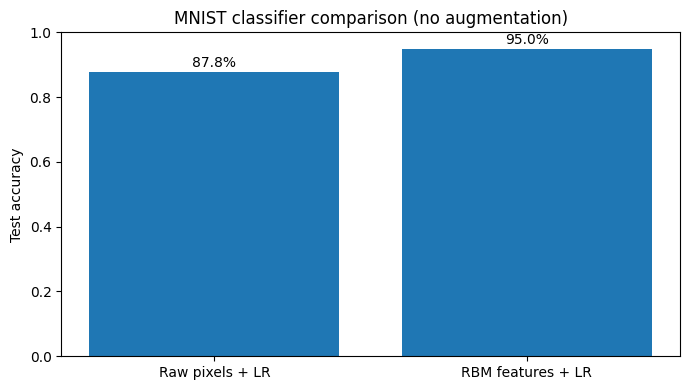

In [47]:
print(f'Raw-pixel Logistic Regression: {raw_accuracy:.3f}')
print(f'RBM + Logistic Regression:  {rbm_accuracy:.3f}')
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(['Raw pixels + LR', 'RBM features + LR'], [raw_accuracy, rbm_accuracy])
ax.set_ylim(0, 1)
ax.set_ylabel('Test accuracy')
ax.set_title('MNIST classifier comparison (no augmentation)')
for i, value in enumerate([raw_accuracy, rbm_accuracy]):
    ax.text(i, value + 0.015, f'{value:.1%}', ha='center')
plt.tight_layout()
plt.show()

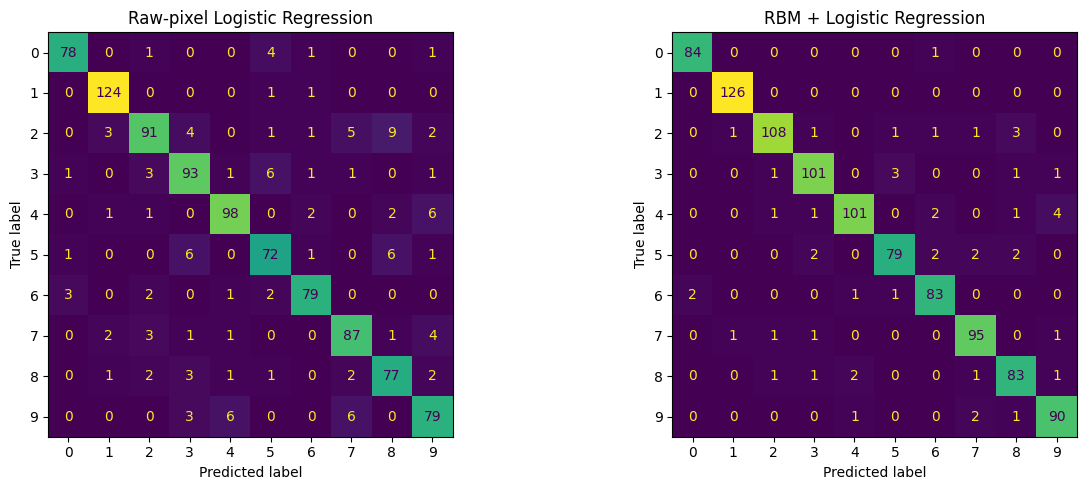

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_raw_pred, ax=axes[0], colorbar=False)
axes[0].set_title('Raw-pixel Logistic Regression')
ConfusionMatrixDisplay.from_predictions(y_test, y_rbm_pred, ax=axes[1], colorbar=False)
axes[1].set_title('RBM + Logistic Regression')
plt.tight_layout()
plt.show()

## RBM output

In [48]:
features = rbm_classifier.named_steps['rbm'].transform(X_test[:3])

In [49]:
print('Original three images:', X_test[:3].shape)
print('RBM transformed features:', features.shape)
print('First 10 features of first image:', np.round(features[0, :10], 3))
print('Actual labels:', y_test[:3])
print('Predicted labels:', rbm_classifier.predict(X_test[:3]))

Original three images: (3, 784)
RBM transformed features: (3, 256)
First 10 features of first image: [0.082 0.945 0.873 0.986 0.094 0.008 0.172 0.073 0.978 0.899]
Actual labels: [7 2 1]
Predicted labels: [7 2 1]


## Visualize learned RBM components

In [52]:
weights = rbm_classifier.named_steps['rbm'].components_
print('RBM weight matrix:', weights.shape)

RBM weight matrix: (256, 784)


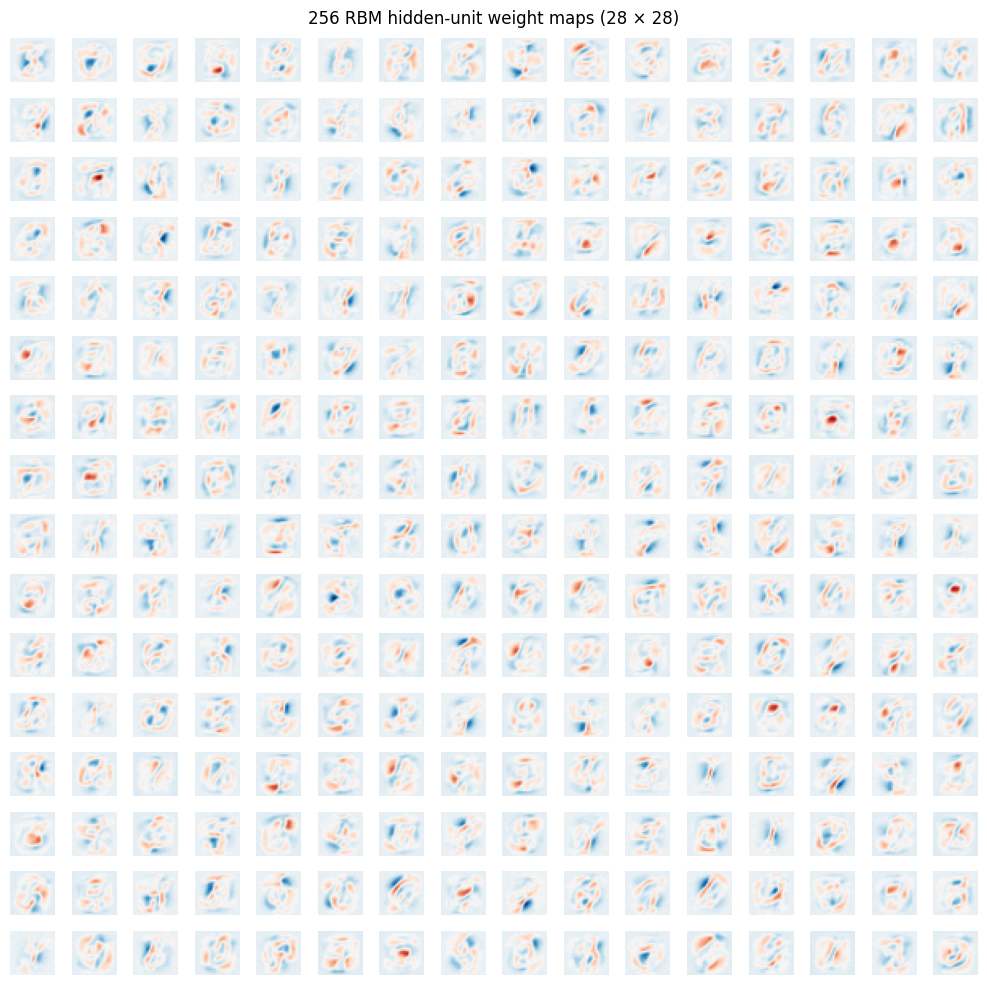

In [56]:
fig, axes = plt.subplots(16, 16, figsize=(10, 10))
lim = np.max(np.abs(weights))

for i, ax in enumerate(axes.flat):
    ax.imshow(weights[i].reshape(28, 28), cmap='RdBu_r', vmin=-lim, vmax=lim)
    ax.axis('off')
plt.suptitle('256 RBM hidden-unit weight maps (28 × 28)')
plt.tight_layout()
plt.show()

In [57]:
items = ["A", "B", "C"]

for i, item in enumerate(items):
    print(f"{i}. {item}")

0. A
1. B
2. C
